#### BOW,TFIDF,Machine Learning Algorithms

1. Preprocessing And Cleaning
2. Train Test Split
3. BOW And TF-IDF (Sentences--->vectors) {Preventing Data Leakage}
4. Trained Our Models


In [1]:
import pandas as pd
messages=pd.read_csv('SpamClassifier/SMSSpamCollection.txt',
                    sep='\t',names=["label","message"])

In [2]:
messages

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [3]:
## Data Cleaning And Preprocessing
import re
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [4]:
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
ps=PorterStemmer()

In [5]:
corpus=[]
for i in range(0,len(messages)):
    review=re.sub('[^a-zA-z]',' ',messages['message'][i])
    review=review.lower()
    review=review.split()
    review=[ps.stem(word) for word in review if not word in stopwords.words('english')]
    review=' '.join(review)
    corpus.append(review)

In [6]:
corpus

['go jurong point crazi avail bugi n great world la e buffet cine got amor wat',
 'ok lar joke wif u oni',
 'free entri wkli comp win fa cup final tkt st may text fa receiv entri question std txt rate c appli',
 'u dun say earli hor u c alreadi say',
 'nah think goe usf live around though',
 'freemsg hey darl week word back like fun still tb ok xxx std chg send rcv',
 'even brother like speak treat like aid patent',
 'per request mell mell oru minnaminungint nurungu vettam set callertun caller press copi friend callertun',
 'winner valu network custom select receivea prize reward claim call claim code kl valid hour',
 'mobil month u r entitl updat latest colour mobil camera free call mobil updat co free',
 'gonna home soon want talk stuff anymor tonight k cri enough today',
 'six chanc win cash pound txt csh send cost p day day tsandc appli repli hl info',
 'urgent week free membership prize jackpot txt word claim c www dbuk net lccltd pobox ldnw rw',
 'search right word thank breather

## Create Bag Of Words

In [7]:
## Output Features
y = (messages['label'] == 'spam').astype(int)

In [8]:
y

0       0
1       0
2       1
3       0
4       0
       ..
5567    1
5568    0
5569    0
5570    0
5571    0
Name: label, Length: 5572, dtype: int64

In [9]:
## Train Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(corpus,y,test_size=0.20,random_state=42)

In [10]:
## Create the Bag OF Words model
from sklearn.feature_extraction.text import CountVectorizer
## for Binary BOW enable binary=True
cv=CountVectorizer(max_features=2500,ngram_range=(1,2))

In [11]:
len(X_train),len(y_train)

(4457, 4457)

In [12]:
## independent features
X_train=cv.fit_transform(X_train).toarray()
X_test=cv.transform(X_test).toarray()

In [13]:
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000, 
    formatter=dict(float=lambda x: "%.3g" % x))
X_train

array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0

In [14]:
cv.vocabulary_

{'repli': np.int64(1719),
 'win': np.int64(2392),
 'weekli': np.int64(2366),
 'world': np.int64(2427),
 'cup': np.int64(456),
 'send': np.int64(1822),
 'stop': np.int64(1988),
 'end': np.int64(586),
 'servic': np.int64(1838),
 'send stop': np.int64(1828),
 'stop end': np.int64(1990),
 'hello': np.int64(914),
 'sort': np.int64(1939),
 'town': np.int64(2175),
 'alreadi': np.int64(51),
 'dont': np.int64(540),
 'rush': np.int64(1765),
 'home': np.int64(950),
 'eat': np.int64(573),
 'let': np.int64(1143),
 'know': np.int64(1087),
 'let know': np.int64(1145),
 'come': np.int64(380),
 'go': np.int64(794),
 'tell': np.int64(2066),
 'told': np.int64(2152),
 'hey': np.int64(917),
 'till': np.int64(2129),
 'dint': np.int64(525),
 'meet': np.int64(1276),
 'even': np.int64(618),
 'singl': np.int64(1880),
 'time': np.int64(2130),
 'saw': np.int64(1786),
 'situat': np.int64(1888),
 'orang': np.int64(1500),
 'bring': np.int64(216),
 'rington': np.int64(1745),
 'free': np.int64(712),
 'hit': np.int64(9

In [15]:
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, ComplementNB

from sklearn.linear_model import LogisticRegression

from sklearn.svm import LinearSVC

from sklearn.ensemble import RandomForestClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.neighbors import KNeighborsClassifier

In [16]:
models = {
    'MultinomialNB': MultinomialNB(),
    'BernoulliNB': BernoulliNB(),
    'ComplementNB': ComplementNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'SVM': LinearSVC(),
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'KNN': KNeighborsClassifier()
}

results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results[name] = y_pred

    print(f"{name} trained successfully")

MultinomialNB trained successfully
BernoulliNB trained successfully
ComplementNB trained successfully
Logistic Regression trained successfully
SVM trained successfully
Random Forest trained successfully
Decision Tree trained successfully
KNN trained successfully


In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

model_results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    model_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
4,SVM,0.985650,0.971631,0.919463,0.944828
3,Logistic Regression,0.985650,0.992593,0.899329,0.943662
1,BernoulliNB,0.985650,1.000000,0.892617,0.943262
0,MultinomialNB,0.983857,0.951724,0.926174,0.938776
5,Random Forest,0.977578,1.000000,0.832215,0.908425
6,Decision Tree,0.972197,0.909722,0.879195,0.894198
2,ComplementNB,0.966816,0.825581,0.953020,0.884735
7,KNN,0.926457,1.000000,0.449664,0.620370


In [18]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:", results_df.iloc[0]['F1 Score'])

Best Model: SVM
Best F1 Score: 0.9448275862068966


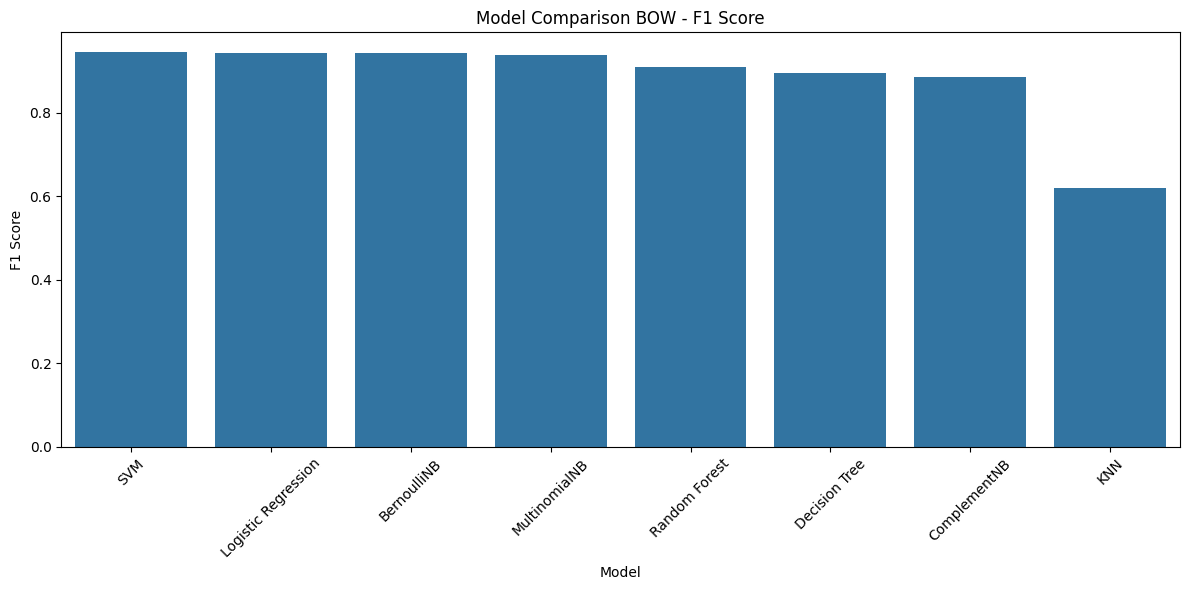

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='F1 Score'
)

plt.xticks(rotation=45)
plt.title('Model Comparison BOW - F1 Score')
plt.tight_layout()
plt.show()

### Creating The TF-IDF Model

In [20]:
## Train Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(corpus,y,test_size=0.20,random_state=42)

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
tv=TfidfVectorizer(max_features=2500,ngram_range=(1,2))
X_train=tv.fit_transform(X_train).toarray()
X_test=tv.transform(X_test).toarray()

In [22]:
X_train

array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..., 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0

In [23]:
tv.vocabulary_

{'repli': np.int64(1719),
 'win': np.int64(2392),
 'weekli': np.int64(2366),
 'world': np.int64(2427),
 'cup': np.int64(456),
 'send': np.int64(1822),
 'stop': np.int64(1988),
 'end': np.int64(586),
 'servic': np.int64(1838),
 'send stop': np.int64(1828),
 'stop end': np.int64(1990),
 'hello': np.int64(914),
 'sort': np.int64(1939),
 'town': np.int64(2175),
 'alreadi': np.int64(51),
 'dont': np.int64(540),
 'rush': np.int64(1765),
 'home': np.int64(950),
 'eat': np.int64(573),
 'let': np.int64(1143),
 'know': np.int64(1087),
 'let know': np.int64(1145),
 'come': np.int64(380),
 'go': np.int64(794),
 'tell': np.int64(2066),
 'told': np.int64(2152),
 'hey': np.int64(917),
 'till': np.int64(2129),
 'dint': np.int64(525),
 'meet': np.int64(1276),
 'even': np.int64(618),
 'singl': np.int64(1880),
 'time': np.int64(2130),
 'saw': np.int64(1786),
 'situat': np.int64(1888),
 'orang': np.int64(1500),
 'bring': np.int64(216),
 'rington': np.int64(1745),
 'free': np.int64(712),
 'hit': np.int64(9

In [24]:
models = {
    'MultinomialNB': MultinomialNB(),
    'BernoulliNB': BernoulliNB(),
    'ComplementNB': ComplementNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'SVM': LinearSVC(),
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'KNN': KNeighborsClassifier()
}

results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results[name] = y_pred

    print(f"{name} trained successfully")

MultinomialNB trained successfully
BernoulliNB trained successfully
ComplementNB trained successfully
Logistic Regression trained successfully
SVM trained successfully
Random Forest trained successfully
Decision Tree trained successfully
KNN trained successfully


In [25]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

model_results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    model_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
4,SVM,0.989238,1.000000,0.919463,0.958042
1,BernoulliNB,0.985650,1.000000,0.892617,0.943262
5,Random Forest,0.982960,1.000000,0.872483,0.931900
0,MultinomialNB,0.980269,0.984733,0.865772,0.921429
3,Logistic Regression,0.974888,1.000000,0.812081,0.896296
2,ComplementNB,0.964126,0.811429,0.953020,0.876543
6,Decision Tree,0.965022,0.898551,0.832215,0.864111
7,KNN,0.928251,1.000000,0.463087,0.633028


In [26]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:", results_df.iloc[0]['F1 Score'])

Best Model: SVM
Best F1 Score: 0.958041958041958


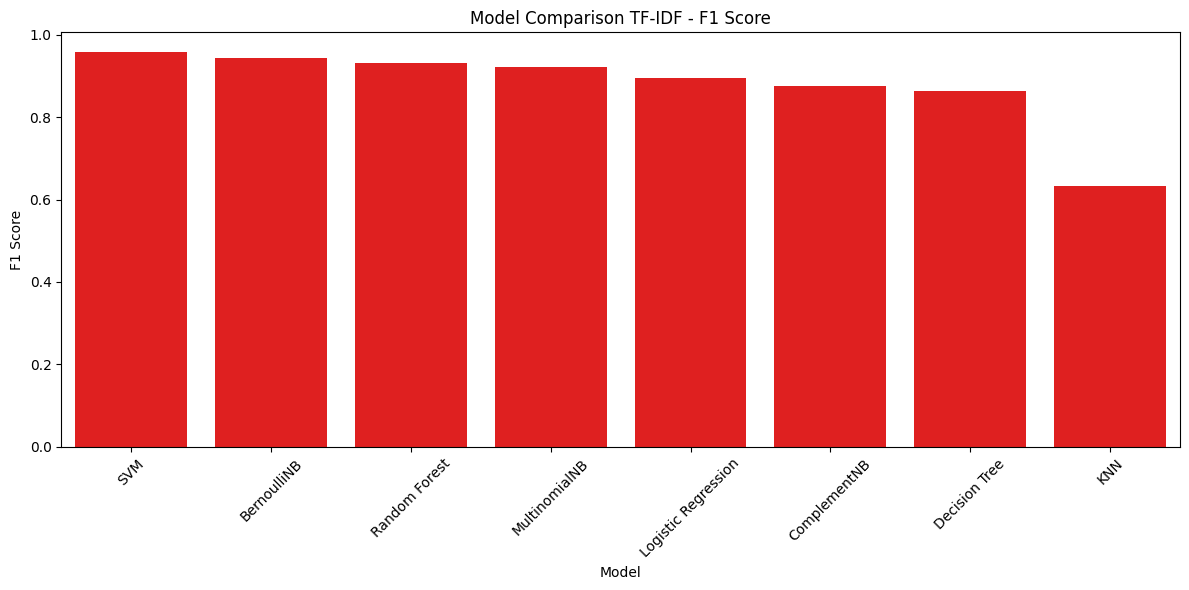

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='F1 Score',
    color="red"
)

plt.xticks(rotation=45)
plt.title('Model Comparison TF-IDF - F1 Score')
plt.tight_layout()
plt.show()